# Import libraries

In [1]:
import spacy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

nlp = spacy.load("en_core_web_md")

print("Model:", nlp.meta["name"])
print("Vector dimensions:", nlp.vocab.vectors_length)

Model: core_web_md
Vector dimensions: 300


# Define 20 words

In [2]:
word_groups = {
    "Animals": [
        "dog", "cat", "wolf", "lion", "tiger"
    ],
    "Vehicles": [
        "car", "truck", "bus", "train", "bicycle"
    ],
    "Technology": [
        "computer", "database", "server", "software", "SQL"
    ],
    "Nature": [
        "tree", "flower", "river", "mountain", "forest"
    ]
}

words = []
categories = []

for category, group in word_groups.items():
    for word in group:
        words.append(word)
        categories.append(category)

print("Number of words:", len(words))

Number of words: 20


# Extract the 300-dimensional vectors

In [3]:
vectors = []

for word in words:
    doc = nlp(word)

    vectors.append(doc.vector)

vectors = np.array(vectors)

print("Shape:", vectors.shape)

Shape: (20, 300)


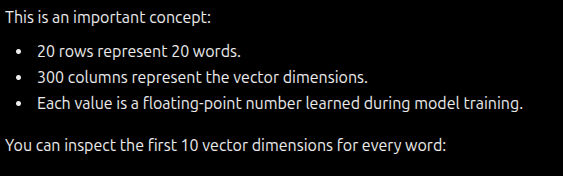

# You can inspect the first 10 vector dimensions for every word:

In [4]:
df_vectors = pd.DataFrame(
    vectors[:, :10],
    index=words,
    columns=[f"Dimension_{i}" for i in range(1, 11)]
)

display(df_vectors.round(4))

,Dimension_1,Dimension_2,Dimension_3,Dimension_4,Dimension_5,Dimension_6,Dimension_7,Dimension_8,Dimension_9,Dimension_10
dog,-0.7248,0.4254,0.0255,-0.3981,0.0375,-0.2981,-0.2828,0.2933,0.5778,1.2205
cat,-0.7248,0.4254,0.0255,-0.3981,0.0375,-0.2981,-0.2828,0.2933,0.5778,1.2205
wolf,-0.7628,-0.2074,0.3212,-0.4582,-0.3604,0.6015,0.7449,0.0797,-0.2343,0.3122
lion,-0.7628,-0.2074,0.3212,-0.4582,-0.3604,0.6015,0.7449,0.0797,-0.2343,0.3122
tiger,-0.7628,-0.2074,0.3212,-0.4582,-0.3604,0.6015,0.7449,0.0797,-0.2343,0.3122
car,-0.6305,-0.0831,-0.0073,-0.3026,0.6679,0.2405,-0.0530,0.0387,0.3173,1.5618
truck,-0.6048,0.3740,0.2845,-0.0163,-0.1189,-0.1971,-0.3512,-0.0657,-0.2187,3.2252
bus,-0.6057,-0.1059,-0.3934,-0.1518,-0.0667,-0.2980,0.2961,-0.4317,0.0718,2.4310
train,-0.6896,0.7111,0.3405,0.2489,0.4286,-0.3139,-0.1246,0.3901,-0.1700,2.0736
bicycle,-0.6171,-0.4956,-0.1491,-0.8429,-0.0376,0.7088,-0.0746,0.2232,0.1321,1.1399


# Reduce 300 dimensions to 2 with PCA

In [5]:
pca = PCA(n_components=2)

vectors_2d = pca.fit_transform(vectors)

print("Original shape:", vectors.shape)
print("Reduced shape:", vectors_2d.shape)

print(
    "Explained variance:",
    pca.explained_variance_ratio_
)

Original shape: (20, 300)
Reduced shape: (20, 2)
Explained variance: [0.19618851 0.11772974]


# Display the words using Matplotlib

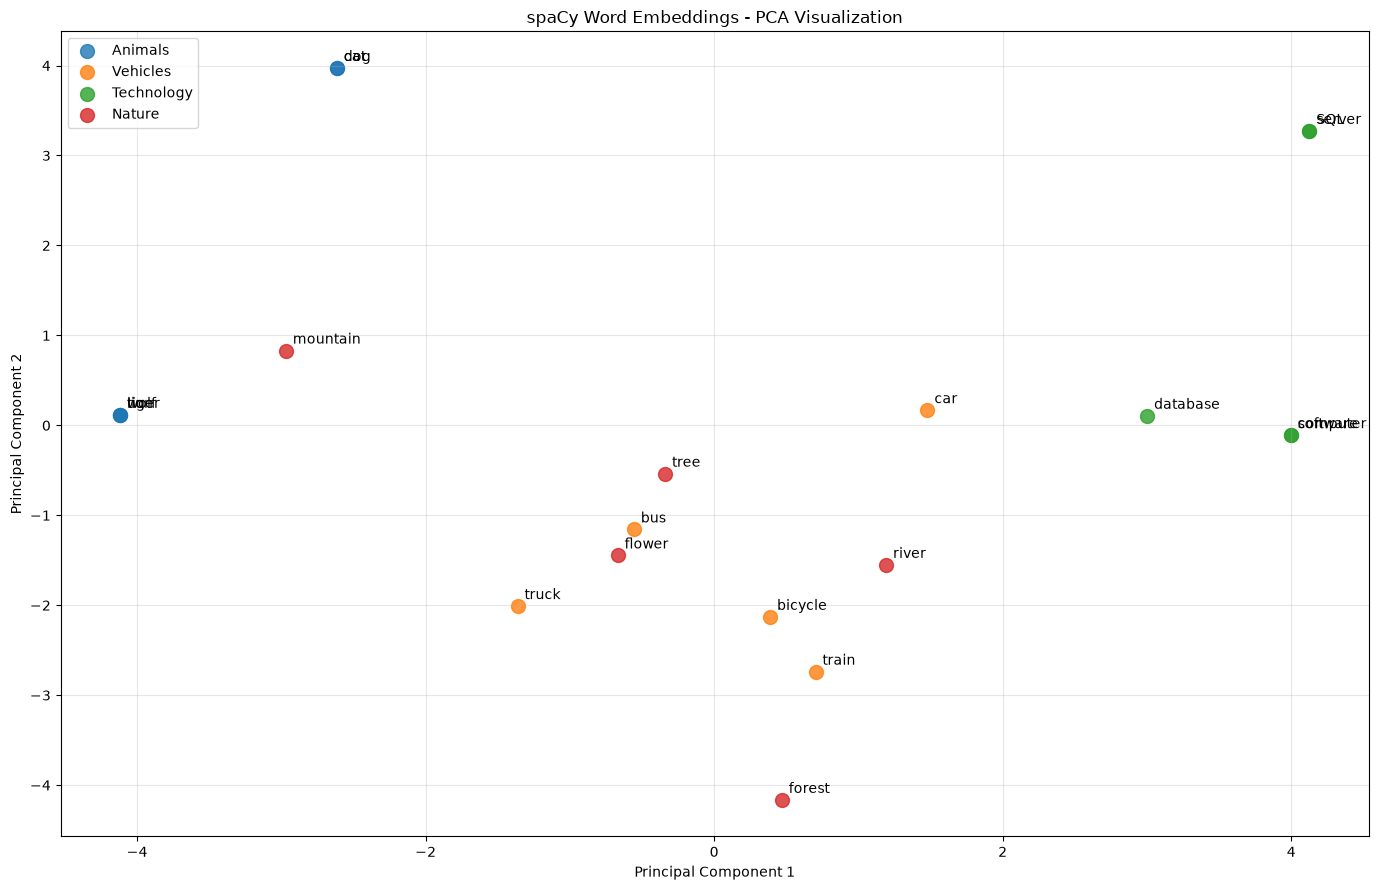

In [6]:
plt.figure(figsize=(14, 9))

for category in word_groups:
    indices = [
        i for i, c in enumerate(categories)
        if c == category
    ]

    plt.scatter(
        vectors_2d[indices, 0],
        vectors_2d[indices, 1],
        s=100,
        label=category,
        alpha=0.8
    )

# Add word labels
for i, word in enumerate(words):
    plt.annotate(
        word,
        (vectors_2d[i, 0], vectors_2d[i, 1]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=10
    )

plt.title("spaCy Word Embeddings - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate actual semantic similarity

In [7]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(vectors)

df_similarity = pd.DataFrame(
    similarity_matrix,
    index=words,
    columns=words
)

display(df_similarity.round(3))

,dog,cat,wolf,lion,tiger,car,truck,bus,train,bicycle,computer,database,server,software,SQL,tree,flower,river,mountain,forest
dog,1.000,1.000,0.311,0.311,0.311,0.193,0.188,0.175,0.082,0.043,0.079,0.041,0.086,0.079,0.086,0.144,0.199,0.113,0.451,-0.029
cat,1.000,1.000,0.311,0.311,0.311,0.193,0.188,0.175,0.082,0.043,0.079,0.041,0.086,0.079,0.086,0.144,0.199,0.113,0.451,-0.029
wolf,0.311,0.311,1.000,1.000,1.000,0.046,0.284,0.214,0.094,0.047,-0.003,-0.022,0.048,-0.003,0.048,0.201,0.113,0.097,0.565,0.147
lion,0.311,0.311,1.000,1.000,1.000,0.046,0.284,0.214,0.094,0.047,-0.003,-0.022,0.048,-0.003,0.048,0.201,0.113,0.097,0.565,0.147
tiger,0.311,0.311,1.000,1.000,1.000,0.046,0.284,0.214,0.094,0.047,-0.003,-0.022,0.048,-0.003,0.048,0.201,0.113,0.097,0.565,0.147
car,0.193,0.193,0.046,0.046,0.046,1.000,0.070,0.210,0.169,0.104,0.194,0.057,0.188,0.194,0.188,0.096,0.059,0.218,0.069,0.039
truck,0.188,0.188,0.284,0.284,0.284,0.070,1.000,0.433,0.355,0.175,0.063,-0.082,0.057,0.063,0.057,0.110,0.089,0.202,0.319,0.127
bus,0.175,0.175,0.214,0.214,0.214,0.210,0.433,1.000,0.217,0.260,0.045,-0.005,0.129,0.045,0.129,0.201,0.077,0.154,0.240,0.029
train,0.082,0.082,0.094,0.094,0.094,0.169,0.355,0.217,1.000,0.072,0.181,0.095,0.034,0.181,0.034,0.053,0.066,0.251,0.072,0.237
bicycle,0.043,0.043,0.047,0.047,0.047,0.104,0.175,0.260,0.072,1.000,0.043,0.064,0.016,0.043,0.016,0.089,0.027,0.057,0.100,0.089


# Visualize

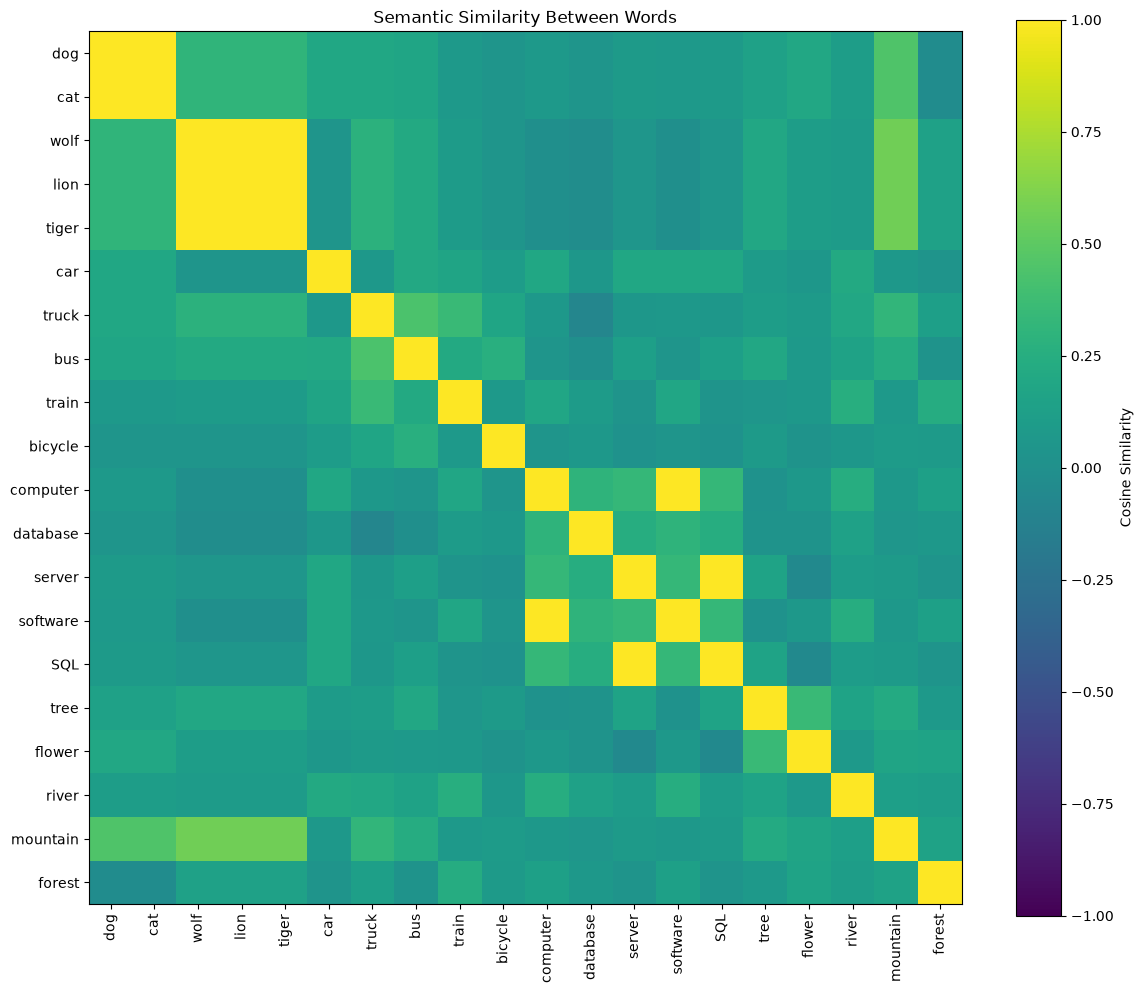

In [8]:
plt.figure(figsize=(12, 10))

plt.imshow(similarity_matrix, cmap="viridis", vmin=-1, vmax=1)

plt.xticks(range(len(words)), words, rotation=90)
plt.yticks(range(len(words)), words)

plt.colorbar(label="Cosine Similarity")
plt.title("Semantic Similarity Between Words")

plt.tight_layout()
plt.show()

# Find the five closest words to "dog"

In [9]:
target_word = "dog"

target_index = words.index(target_word)

similarities = similarity_matrix[target_index]

results = []

for i, word in enumerate(words):
    if word != target_word:
        results.append((word, similarities[i]))

results.sort(key=lambda x: x[1], reverse=True)

print(f"Words most similar to '{target_word}':")

for word, score in results[:5]:
    print(f"{word:15s} {score:.4f}")

Words most similar to 'dog':
cat             1.0000
mountain        0.4512
wolf            0.3108
lion            0.3108
tiger           0.3108
